# 04 · SFT Training: Qwen2.5-0.5B → function calling (QLoRA)

**Goal:** fine-tune on `data/sft/` and score the result **exactly** like the baseline (`03_baseline_eval`): same frozen benchmark, same prompt (`src/prompts.py`), same generator (`src/generation.py`) and same scorer (`src/evaluate.py`).

### How to run (one GPU run per day, so it has to work first time)
1. **`SMOKE_TEST = True` → Run All (~5–10 min).** A dry run of *every* cell: 10 steps on the **longest** examples (worst-case VRAM), save, merge, generate, score, save. It prints peak VRAM and an estimate of the full run time.
2. **`SMOKE_TEST = False` → Run All** and leave it. Smoke outputs go to separate `*_smoke` folders, so they never mix with real results.

### What's fixed compared with `Training_SFT_cleaned`
| Problem | Fix |
|---|---|
| `MAX_SEQ_LENGTH = 512` silently dropped 46% of the training data | read `1536` from `sft_data_report.json` (the data-prep decision, 99.5% coverage) + assert that **nothing** is dropped |
| inference prompt had no system prompt (Qwen inserts its own default) | eval uses `src.prompts.build_messages`, the same as the baseline and the training data |
| best checkpoint could be deleted | `load_best_model_at_end` on eval loss |
| a crash or sleeping laptop = lost day | resumes automatically from the last checkpoint |
| eval crashed after training (Unsloth patches `transformers` for the whole kernel) | generation runs in a fresh process via `src/generate_cli.py` |
| 4-bit `numel()` parameter counts were confusing | explained below and `print_trainable_parameters()` used instead |

## 0. Environment
This is a quick check that the training environment works. **`unsloth` is imported first** because it patches `transformers`/`trl`, and the patches only apply cleanly if nothing has imported those yet.

In [1]:
import unsloth                                   # must come before transformers / trl / peft
import gc
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import peft
import torch
import transformers
import trl

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Unsloth:", unsloth.__version__)
print("Transformers:", transformers.__version__)
print("TRL:", trl.__version__)
print("PEFT:", peft.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

# find the repo root (folder containing src/) and the data folder, wherever this notebook lives
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "splits").is_dir())
sys.path.insert(0, str(REPO_ROOT))

from src.data_utils import read_jsonl, verify_hashes                # noqa: E402
from src.prompts import PROMPT_VERSION, build_messages              # noqa: E402

print("\nRepo root:", REPO_ROOT)
print("Data dir: ", DATA_DIR)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1008 02:37:50.615000 26712 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


🦥 Unsloth Zoo will now patch everything to make training faster!
Python: 3.12.13
PyTorch: 2.11.0+cu130
Unsloth: 2026.8.4
Transformers: 5.5.0
TRL: 0.24.0
PEFT: 0.20.0
CUDA available: True
CUDA: 13.0
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.0 GB

Repo root: c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning
Data dir:  c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data


## 1. Config
- **`SMOKE_TEST`**: the only line you change between the dry run and the real run.
- **`NUM_EPOCHS = 1`**: 48k examples of very templated data. One epoch is usually enough, and it fits the daily GPU window. If val loss is still falling at the end, try 2 epochs in a new run.
- **Effective batch = `BATCH_SIZE × GRAD_ACCUM` = 16.** Batch 2 keeps the longest 1536-token examples within 6 GB.
- **`MAX_SEQ_LENGTH` is not typed here.** It's read from the data-prep report, so training can never disagree with the data again. The file hashes are checked too.

In [2]:
SMOKE_TEST = False         # True = 5-10 min dry run of everything. False = the real run.

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
RUN_NAME = "sft_qwen2.5-0.5b"
BENCHMARK = "test_v1"      # must match the baseline run
SEED = 3407

# LoRA
LORA_R = 16
LORA_ALPHA = 32

# training
NUM_EPOCHS = 1
BATCH_SIZE = 2
GRAD_ACCUM = 8             # effective batch = 16
LEARNING_RATE = 2e-4
EVAL_EVERY = 200           # steps between eval-loss checks (= checkpoint interval)
SMOKE_STEPS = 10

# --- from the data-prep stage: never retype these ---
sft_report = json.loads((DATA_DIR / "sft" / "sft_data_report.json").read_text())
MAX_SEQ_LENGTH = sft_report["max_seq_len"]
RESPONSE_MARKER = sft_report["response_marker"]          # "<|im_start|>assistant\n"
assert sft_report["prompt_version"] == PROMPT_VERSION, "SFT data was built with a different prompt version"
verify_hashes(DATA_DIR / "sft", sft_report["files"])     # train/val.jsonl unchanged since data prep

# --- paths ---
if SMOKE_TEST:
    RUN_NAME += "_smoke"
OUTPUT_DIR = DATA_DIR.parent / "outputs" / RUN_NAME       # checkpoints (gitignored)
ADAPTER_DIR = OUTPUT_DIR / "adapter"                      # final LoRA adapter (small)
MERGED_DIR = OUTPUT_DIR / "merged"                        # base + adapter in bf16, used for eval and DPO
EVAL_DIR = DATA_DIR / "eval"
RESULTS_DIR = EVAL_DIR / "results" / RUN_NAME
BASE_RESULTS_DIR = EVAL_DIR / "results" / "base_qwen2.5-0.5b"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"{'SMOKE TEST' if SMOKE_TEST else 'REAL RUN'} -> {RUN_NAME}")
print("Model:", MODEL_NAME)
print(f"Max sequence length: {MAX_SEQ_LENGTH} (from data prep)")
print("Prompt version:", PROMPT_VERSION, "| data hashes ✅")
print("Seed:", SEED)

REAL RUN -> sft_qwen2.5-0.5b
Model: Qwen/Qwen2.5-0.5B-Instruct
Max sequence length: 1536 (from data prep)
Prompt version: v1 | data hashes ✅
Seed: 3407


# Part A · Train

## 2. Load the base model
We use the **Instruct** checkpoint because the task is instruction → structured tool call. Unsloth returns the model-matched tokenizer, and that's the one SFT uses.

Things to check in the output: the chat template exists, EOS is `<|im_end|>` (generation stops there), and PAD is **not** EOS. If they were the same, padding positions could be confused with "stop" positions.

In [3]:
from unsloth import FastLanguageModel, is_bfloat16_supported

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    load_in_4bit=True,
    dtype=None,                      # auto -> bf16 on the RTX 4050
)

print("Model loaded.")
print("Chat template available:", tokenizer.chat_template is not None)
print("EOS:", tokenizer.eos_token, "| ID:", tokenizer.eos_token_id)
print("PAD:", tokenizer.pad_token, "| ID:", tokenizer.pad_token_id)

==((====))==  Unsloth 2026.8.4: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    NVIDIA GeForce RTX 4050 Laptop GPU. Num GPUs = 1. Max memory: 5.997 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 8.9. CUDA Toolkit: 13.0. Triton: 3.7.1
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded.
Chat template available: True
EOS: <|im_end|> | ID: 151645
PAD: <|vision_pad|> | ID: 151654


## 3. Parameter inspection — total vs trainable BEFORE QLoRA
Before LoRA, the model contains **all base-model parameters**. With QLoRA those stay frozen and small trainable LoRA matrices are added on top.

- **Total parameters** = size of the original model
- **Trainable parameters** = what SFT actually updates
- **Trainable %** = how much of the model we're learning

**The 4-bit counting trap:** `bitsandbytes` packs **two** 4-bit weights into one byte, so `p.numel()` counts every quantized matrix at **half** its real size. That's why the earlier notebook showed 342M, 351M *and* 502M. The cell below prints both the raw count and the corrected one (packed tensors × 2), so you can see the difference.

In [4]:
def count_params(model):
    raw = sum(p.numel() for p in model.parameters())
    # Params4bit = packed 4-bit weights -> each stored element holds 2 real weights
    real = sum(p.numel() * (2 if p.__class__.__name__ == "Params4bit" else 1) for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return raw, real, trainable

raw, real, trainable = count_params(model)
before = {"total (numel, packed)": raw, "total (real)": real, "trainable": trainable}
print(f"numel() total (packed, misleading): {raw:,}")
print(f"Real total (4-bit corrected):       {real:,}")
print(f"Trainable right now:                {trainable:,}  ({100 * trainable / real:.2f}%)")
print("\n(anything 'trainable right now' is non-quantized weights still flagged trainable; get_peft_model freezes all of it except LoRA)")

numel() total (packed, misleading): 342,185,856
Real total (4-bit corrected):       494,032,768
Trainable right now:                54,204,288  (10.97%)

(anything 'trainable right now' is non-quantized weights still flagged trainable; get_peft_model freezes all of it except LoRA)


### Parameter names and shapes
One or two names show how the Transformer is organised and where names like `q_proj` and `gate_proj` (our LoRA targets) come from. Note the quantized `q_proj` shape: it's packed, not the real 896×896.

In [5]:
for name, param in model.named_parameters():
    print(f"{name:60s} {str(tuple(param.shape)):18s} {param.__class__.__name__}")
    if "layers.0.self_attn.q_proj.weight" in name:
        break

model.embed_tokens.weight                                    (151936, 896)      Parameter
model.layers.0.self_attn.q_proj.weight                       (896, 896)         Parameter


## 4. Apply LoRA / QLoRA
- `r`: LoRA rank. Higher rank = more adapter capacity and more trainable parameters.
- `lora_alpha`: scaling applied to the LoRA update (effective scale = `alpha / r` = 2 here).
- `lora_dropout = 0.0`: what Unsloth's fused kernels are optimised for.
- `target_modules`: every linear projection, attention **and** MLP.
- `bias="none"`: biases are not trained.
- `use_gradient_checkpointing="unsloth"`: recomputes activations instead of storing them, which saves VRAM.

For a linear layer `d_in → d_out`, LoRA learns **A: `r × d_in`** and **B: `d_out × r`** instead of a full `d_out × d_in` update:

**trainable ≈ `r × (d_in + d_out)`**. For `q_proj` (896→896, r=16) that's 28,672 instead of 802,816, about 28× fewer.

In [6]:
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

model = FastLanguageModel.get_peft_model(
    model,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=0.0,
    target_modules=TARGET_MODULES,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)
model.print_trainable_parameters()      # PEFT's own count, already 4-bit corrected

Unsloth 2026.8.4 patched 24 layers with 24 QKV layers, 24 O layers and 24 MLP layers.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


### Verify what became trainable — AFTER QLoRA
Only `lora_A` / `lora_B` should show up. Check the formula on a real layer: `k_proj` is 896→128, so `lora_A` = 16×896 = 14,336 and `lora_B` = 128×16 = 2,048.

In [7]:
trainable_params = [(name, p.numel()) for name, p in model.named_parameters() if p.requires_grad]
raw, real, trainable = count_params(model)

print(f"Real total:   {real:,}")
print(f"Trainable:    {trainable:,}  ({100 * trainable / real:.2f}%)")
print(f"Only LoRA params trainable: {all('lora_' in n for n, _ in trainable_params)}")

print("\nSample trainable parameters:")
for name, n in trainable_params[:10]:
    print(f"{name:80s} {n:,}")

Real total:   502,830,976
Trainable:    8,798,208  (1.75%)
Only LoRA params trainable: True

Sample trainable parameters:
base_model.model.model.layers.0.self_attn.q_proj.lora_A.default.weight           14,336
base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight           14,336
base_model.model.model.layers.0.self_attn.k_proj.lora_A.default.weight           14,336
base_model.model.model.layers.0.self_attn.k_proj.lora_B.default.weight           2,048
base_model.model.model.layers.0.self_attn.v_proj.lora_A.default.weight           14,336
base_model.model.model.layers.0.self_attn.v_proj.lora_B.default.weight           2,048
base_model.model.model.layers.0.self_attn.o_proj.lora_A.default.weight           14,336
base_model.model.model.layers.0.self_attn.o_proj.lora_B.default.weight           14,336
base_model.model.model.layers.0.mlp.gate_proj.lora_A.default.weight              14,336
base_model.model.model.layers.0.mlp.gate_proj.lora_B.default.weight              77,824


### Total vs trainable: before and after QLoRA
The whole point of PEFT in one table: the model gets slightly **bigger** (the adapters are added), but the trainable part goes from "whatever wasn't frozen" to **only the LoRA matrices**.

In [8]:
after = {"total (numel, packed)": raw, "total (real)": real, "trainable": trainable}
param_table = pd.DataFrame({"before QLoRA": before, "after QLoRA": after})
param_table.loc["trainable %"] = [100 * before["trainable"] / before["total (real)"],
                                  100 * after["trainable"] / after["total (real)"]]
param_table.style.format(
    "{:,.0f}",
    subset=pd.IndexSlice[["total (numel, packed)", "total (real)", "trainable"], :],  # type: ignore
).format(
    "{:.2f}%",
    subset=pd.IndexSlice[["trainable %"], :],  # type: ignore
)

,before QLoRA,after QLoRA
"total (numel, packed)","342,185,856","350,984,064"
total (real),"494,032,768","502,830,976"
trainable,"54,204,288","8,798,208"
trainable %,10.97%,1.75%


### What one LoRA-wrapped layer looks like
One decoder layer instead of the whole 24-layer printout. Each projection is now `base_layer` (frozen, 4-bit) + `lora_A` → `lora_B` (trainable).

In [9]:
print(model.base_model.model.model.layers[0])

Qwen2DecoderLayer(
  (self_attn): Qwen2Attention(
    (q_proj): lora.Linear(
      (base_layer): Linear(in_features=896, out_features=896, bias=True)
      (lora_dropout): ModuleDict(
        (default): Identity()
      )
      (lora_A): ModuleDict(
        (default): Linear(in_features=896, out_features=16, bias=False)
      )
      (lora_B): ModuleDict(
        (default): Linear(in_features=16, out_features=896, bias=False)
      )
      (lora_embedding_A): ParameterDict()
      (lora_embedding_B): ParameterDict()
      (lora_magnitude_vector): ModuleDict()
    )
    (k_proj): lora.Linear(
      (base_layer): Linear(in_features=896, out_features=128, bias=True)
      (lora_dropout): ModuleDict(
        (default): Identity()
      )
      (lora_A): ModuleDict(
        (default): Linear(in_features=896, out_features=16, bias=False)
      )
      (lora_B): ModuleDict(
        (default): Linear(in_features=16, out_features=128, bias=False)
      )
      (lora_embedding_A): ParameterDict(

## 5. Data
- `.rstrip()` makes every example end **exactly** on `<|im_end|>`. With a trailing `\n`, TRL can decide the text "doesn't end with EOS" and append a second one.
- Only the `text` column is kept. With a `messages` column present, TRL may treat the dataset as a chat dataset and re-apply the template itself (a second formatting path we don't want).
- **Smoke test** uses the 160 **longest** examples, so the VRAM it measures is the worst case.

In [10]:
from typing import Any, cast

from datasets import load_dataset

dataset = load_dataset("json", data_files={
    "train": str(DATA_DIR / "sft" / "train.jsonl"),
    "validation": str(DATA_DIR / "sft" / "val.jsonl"),
})
dataset = dataset.map(lambda x: {"text": x["text"].rstrip()})
dataset = cast(Any, dataset.remove_columns(["id", "messages"]))

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 48616
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 1169
    })
})


## 6. Minimal dataset sanity checks
Before spending GPU time, verify that:
1. the `text` field exists,
2. there are no empty examples,
3. the example really has the system → user → assistant structure, **with our system prompt** (not Qwen's default).

In [11]:
for split in ["train", "validation"]:
    split_data = cast(Any, dataset[split])
    assert "text" in split_data.column_names
    empty = sum(not t.strip() for t in split_data["text"])
    print(f"{split}: {len(split_data):,} examples | empty: {empty}")
    assert empty == 0

train_split = cast(Any, dataset["train"])
sample_text = train_split[0]["text"]
assert sample_text.startswith("<|im_start|>system\nYou are a function-calling assistant")
assert "You are Qwen" not in sample_text
assert sample_text.endswith("<|im_end|>")

print("\nSample training example:")
print(sample_text)

train: 48,616 examples | empty: 0
validation: 1,169 examples | empty: 0

Sample training example:
<|im_start|>system
You are a function-calling assistant.

Your task is to select the appropriate tool and provide the arguments required
to answer the user's request.

Return ONLY valid JSON.

The output must be a JSON array of tool calls in this format:

[
  {
    "name": "function_name",
    "arguments": {
      "argument_name": "value"
    }
  }
]

If none of the available tools can answer the request, return an empty array: []

Do not explain your answer.
Do not output markdown.
Do not invent tools.
<|im_end|>
<|im_start|>user
Available tools:

[
  {
    "name": "live_giveaways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

User request

## 7. Token-length sanity check
This is the check that **caught the 512 bug**: 273 of 500 examples were over the limit. With `MAX_SEQ_LENGTH = 1536` from data prep, this should now say **0**. The data-prep percentiles are printed alongside so you can compare.

In [12]:
train_data = cast(Any, dataset["train"])
audit = train_data.select(range(min(500, len(train_data))))
lengths = [len(tokenizer(t, add_special_tokens=False)["input_ids"]) for t in audit["text"]]

print("Checked:", len(lengths), "training examples")
print("Max length: ", max(lengths))
print("Mean length:", round(sum(lengths) / len(lengths), 1))
print(f"Over MAX_SEQ_LENGTH ({MAX_SEQ_LENGTH}):", sum(x > MAX_SEQ_LENGTH for x in lengths))
print("Data-prep percentiles (full train set):", sft_report["train_token_percentiles"])
assert max(lengths) <= MAX_SEQ_LENGTH

Checked: 500 training examples
Max length:  1503
Mean length: 585.7
Over MAX_SEQ_LENGTH (1536): 0
Data-prep percentiles (full train set): {'0.5': 539, '0.9': 923, '0.95': 1075, '0.99': 1328, '0.995': 1404, '1.0': 1615}


### Train/val sets for this run
Smoke test: the 160 **longest** training examples (worst-case VRAM) + 50 val. Real run: everything.

In [13]:
train_ds, val_ds = dataset["train"], dataset["validation"]
full_train_chars = sum(len(t) for t in cast(Any, train_ds)["text"])  # used for the time estimate

if SMOKE_TEST:
    char_lengths = [len(t) for t in cast(Any, train_ds)["text"]]
    longest = sorted(range(len(char_lengths)), key=lambda i: char_lengths[i], reverse=True)
    train_ds = cast(Any, train_ds).select(longest[: SMOKE_STEPS * BATCH_SIZE * GRAD_ACCUM])
    val_ds = cast(Any, val_ds).select(range(50))
    val_ds = val_ds.select(range(50))

print(f"train: {len(cast(Any, train_ds)):,} | val: {len(cast(Any, val_ds)):,}")

train: 48,616 | val: 1,169


## 8. SFT configuration + trainer
- **bf16** because the model was loaded in bf16 (that was the original `TypeError`).
- **`train_on_responses_only`**: loss only on the JSON answer. The system prompt and tool list are ~90% of each example (`median_share_of_tokens_trained` = 9% in the data report), so without masking most of the gradient would go into memorizing boilerplate.
- **`load_best_model_at_end`**: the HF version of the early-stopping-on-val-loss you wrote by hand for SmolLM2. `save_total_limit=2` keeps the best checkpoint plus the latest one.

In [14]:
from trl.trainer.sft_config import SFTConfig
from trl.trainer.sft_trainer import SFTTrainer
from unsloth.chat_templates import train_on_responses_only

eval_every = 5 if SMOKE_TEST else EVAL_EVERY

training_args = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=NUM_EPOCHS,
    max_steps=SMOKE_STEPS if SMOKE_TEST else -1,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=GRAD_ACCUM,

    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=0.03,                 # < 1 means a ratio of total steps
    weight_decay=0.01,
    optim="adamw_8bit",

    bf16=is_bfloat16_supported(),
    fp16=not is_bfloat16_supported(),

    logging_steps=1 if SMOKE_TEST else 10,
    eval_strategy="steps",
    eval_steps=eval_every,
    save_strategy="steps",
    save_steps=eval_every,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    dataset_text_field="text",
    max_length=MAX_SEQ_LENGTH,
    packing=False,
    seed=SEED,
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=cast(Any, train_ds),
    eval_dataset=cast(Any, val_ds),
    args=training_args,
)
trainer = train_on_responses_only(
    trainer,
    instruction_part="<|im_start|>user\n",
    response_part=RESPONSE_MARKER,
)

Unsloth: Tokenizing ["text"]:   0%|          | 0/1169 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/1169 [00:00<?, ? examples/s]

## 9. Label-masking sanity check (before spending GPU hours)
If any of these fail, **stop**. They are the bugs that cost a whole training day:
1. **No example was dropped.** With 512 tokens, Unsloth dropped 22k.
2. **Only the answer is trained:** the unmasked tokens decode to exactly `answer + <|im_end|>`. That's the same check as in data prep, now run on what the trainer will *actually* use.

In [15]:
assert trainer.train_dataset is not None
assert trainer.eval_dataset is not None
trainer_train_dataset = cast(Any, trainer.train_dataset)
trainer_eval_dataset = cast(Any, trainer.eval_dataset)

assert len(trainer_train_dataset) == len(cast(Any, train_ds)), \
    f"{len(cast(Any, train_ds)) - len(trainer_train_dataset)} train examples dropped - is MAX_SEQ_LENGTH too small?"
assert len(trainer_eval_dataset) == len(cast(Any, val_ds)), \
    f"{len(cast(Any, val_ds)) - len(trainer_eval_dataset)} val examples dropped"

def trained_part(row):
    return tokenizer.decode([t for t, l in zip(row["input_ids"], row["labels"]) if l != -100])

train_ds_any = cast(Any, train_ds)
trainer_train_ds_any = cast(Any, trainer_train_dataset)

for i in range(min(200, len(train_ds_any))):
    expected = train_ds_any[i]["text"].split(RESPONSE_MARKER)[-1]  # JSON answer + <|im_end|>
    got = trained_part(trainer_train_ds_any[i])
    assert got == expected, f"row {i}: trained on\n{got!r}\nexpected\n{expected!r}"

row = trainer_train_dataset[0]
n_trained = sum(l != -100 for l in row["labels"])
print(f"✅ nothing dropped ({len(trainer_train_dataset):,} train / {len(trainer_eval_dataset):,} val)")
print(f"✅ only the answer is trained, e.g. {n_trained} of {len(row['labels'])} tokens: {trained_part(row)!r}")

✅ nothing dropped (48,616 train / 1,169 val)
✅ only the answer is trained, e.g. 44 of 282 tokens: '[{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}, {"name": "live_giveaways_by_type", "arguments": {"type": "game"}}]<|im_end|>'


## 10. Train
Before the real run: **plug the laptop in and set Windows sleep to "Never"**. If it still crashes, re-run the notebook. It **resumes from the last checkpoint** (saved every 200 steps) instead of starting over.

The adapter is saved straight after training, so Part B can be re-run later without retraining.

In [16]:
from transformers.trainer_utils import get_last_checkpoint

last_checkpoint = get_last_checkpoint(str(OUTPUT_DIR)) if OUTPUT_DIR.exists() else None
print("Resuming from", last_checkpoint if last_checkpoint else "scratch")

torch.cuda.reset_peak_memory_stats()
train_result = trainer.train(resume_from_checkpoint=last_checkpoint)
peak_train_vram = torch.cuda.max_memory_allocated() / 1024**3

model.save_pretrained(str(ADAPTER_DIR))         # best checkpoint (load_best_model_at_end)
tokenizer.save_pretrained(str(ADAPTER_DIR))
(RESULTS_DIR / "train_log.json").write_text(json.dumps(trainer.state.log_history, indent=2))

print(f"\nTrain loss:      {train_result.training_loss:.4f}")
print(f"Best eval loss:  {trainer.state.best_metric:.4f}  ({trainer.state.best_model_checkpoint})")
print(f"Runtime:         {train_result.metrics['train_runtime'] / 3600:.2f} h")
print(f"Peak VRAM:       {peak_train_vram:.2f} GB of 6")
print(f"Adapter saved -> {ADAPTER_DIR}")

if SMOKE_TEST:
    smoke_chars = sum(len(t) for t in cast(Any, train_ds)["text"])
    est_hours = train_result.metrics["train_runtime"] / smoke_chars * full_train_chars * NUM_EPOCHS / 3600
    print(f"\n⏱  Full run estimate: ~{est_hours:.1f} h of training (upper bound: smoke used the longest examples)")
    print("   + evaluation: about 45 min on test_v1 (the baseline took ~0.95 s/question)")
    if peak_train_vram > 5.5:
        print("⚠️  Peak VRAM is close to 6 GB. Set BATCH_SIZE=1, GRAD_ACCUM=16 for the real run.")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Resuming from c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-2000


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 48,616 | Num Epochs = 1 | Total steps = 3,039
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 8 x 1) = 16
 "-____-"     Trainable parameters = 8,798,208 of 502,830,976 (1.75% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
2200,0.039386,0.039556
2400,0.024545,0.038594
2600,0.030160,0.038488
2800,0.017931,0.038232
3000,0.056667,0.038108
3039,0.032208,0.038077


Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-2200\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-2400\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-2600\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-2800\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-3000\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM


Train loss:      0.0122
Best eval loss:  0.0381  (c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\checkpoint-3039)
Runtime:         6.67 h
Peak VRAM:       5.48 GB of 6
Adapter saved -> c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\adapter


### Loss curves
What you want to see: eval loss falls and then flattens. If it **rises** while train loss keeps falling, that's overfitting. `load_best_model_at_end` already kept the best checkpoint, so you're protected either way.

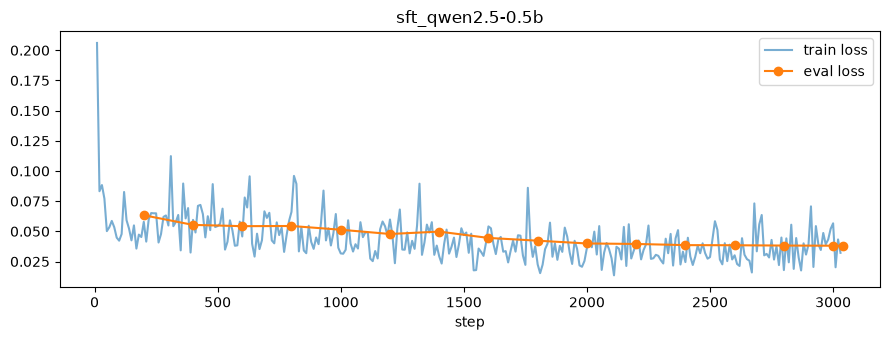

In [17]:
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(9, 3.5))
log.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax, label="train loss", alpha=0.6)
log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=ax, label="eval loss", marker="o")
ax.set_title(f"{RUN_NAME}")
plt.tight_layout()
plt.show()

## 11. Post-training parameter summary
This answers one engineering question: **how big is the base model, and how much did we actually train?** The adapter folder is tiny compared with the model because the original weights never changed.

In [18]:
raw, real, trainable = count_params(model)
adapter_mb = sum(f.stat().st_size for f in ADAPTER_DIR.glob("*.safetensors")) / 1024**2

print(f"Base + LoRA parameters (real): {real:,}")
print(f"Trained LoRA parameters:       {trainable:,}")
print(f"Trainable percentage:          {100 * trainable / real:.2f}%")
print(f"Adapter on disk:               {adapter_mb:.1f} MB  (vs ~1 GB for the full bf16 model)")

Base + LoRA parameters (real): 502,830,976
Trained LoRA parameters:       8,798,208
Trainable percentage:          1.75%
Adapter on disk:               33.6 MB  (vs ~1 GB for the full bf16 model)


# Part B · Evaluate (identical to the baseline)
**Restarted the kernel, or the eval crashed?** Run sections 0 and 1, then continue from here. Part B only needs the saved adapter.

## 12. Merge the adapter, in a fresh process
**Why a separate process?** When Unsloth loads a model, it replaces the forward functions of the `transformers` model **classes** (`Qwen2Attention` …) for the *whole Python process*. A plain `transformers` model loaded afterwards in this kernel runs Unsloth's code and crashes (`'Qwen2Attention' object has no attribute 'apply_qkv'`, which is what the first smoke run hit).

So every generation step runs `src/generate_cli.py` in a **new Python process** that never imports Unsloth. It loads the model exactly like `03_baseline_eval` (bf16, plain `transformers`) and calls the same `run_generation`. Scoring stays here in the notebook.

This step: load the bf16 base, apply the adapter, **merge**, and save. The merged model is what we evaluate, and it's the starting point for DPO.

In [19]:
import os
import subprocess

from src.evaluate import (breakdown, compare_runs, extract_json, failure_mix,      # noqa: E402
                          normalize_calls, query_template, score_generations, summarize, tag_features)

# free the training model's GPU memory: the child process needs it
trainer = model = None
gc.collect()
torch.cuda.empty_cache()

GEN_DIR = OUTPUT_DIR / "gen_inputs"          # temp inputs for the child process (gitignored)
GEN_DIR.mkdir(parents=True, exist_ok=True)


def run_cli(args):
    # run src.generate_cli in a fresh Python process and stream its output here
    cmd = [sys.executable, "-u", "-m", "src.generate_cli", *map(str, args)]
    proc = subprocess.Popen(cmd, cwd=REPO_ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace",
                            env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    if proc.stdout is None:
        raise RuntimeError("generation process stdout pipe was not created")
    for line in proc.stdout:
        print(line, end="")
    assert proc.wait() == 0, "generation process failed - see the output above"


def generate(records, name, run_config, prompt="tools", max_new_tokens=512, stop_at_json=True):
    # generate with the merged model in a fresh process; returns {id: row}, like run_generation
    records_path, config_path = GEN_DIR / f"{name}_records.jsonl", GEN_DIR / f"{name}_config.json"
    with records_path.open("w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    config_path.write_text(json.dumps(run_config))

    out_path = RESULTS_DIR / f"{name}.jsonl"
    args = ["--model", MERGED_DIR, "--records", records_path, "--out", out_path,
            "--run-config-file", config_path, "--prompt", prompt, "--max-new-tokens", max_new_tokens]
    if not stop_at_json:
        args.append("--no-json-stop")
    run_cli(args)
    return {row["id"]: row for row in read_jsonl(out_path)}


run_cli(["--model", MODEL_NAME, "--adapter", ADAPTER_DIR, "--merged-out", MERGED_DIR])

# frozen benchmark: refuse to run if it changed since the baseline
manifest = json.loads((EVAL_DIR / "manifest.json").read_text())
verify_hashes(EVAL_DIR, manifest["files"])
test_records = read_jsonl(EVAL_DIR / f"{BENCHMARK}.jsonl")
if SMOKE_TEST:
    test_records = test_records[:32]
records_by_id = {r["id"]: r for r in test_records}
base_df_full = pd.read_csv(BASE_RESULTS_DIR / "scored.csv")

MAX_NEW_TOKENS = 512
RUN_CONFIG = {
    "model": f"{MODEL_NAME} + {RUN_NAME} (merged LoRA)", "benchmark": BENCHMARK,
    "benchmark_sha256": manifest["files"][f"{BENCHMARK}.jsonl"]["sha256"],
    "prompt_version": PROMPT_VERSION, "max_new_tokens": MAX_NEW_TOKENS, "decoding": "greedy",
}

c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\huggingface_hub\constants.py:298: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
W1008 09:20:24.480000 15488 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 167.39it/s]

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.50s/it]
Merged bf16 model saved -> c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\sft_qwen2.5-0.5b\merged


## 13. Inference sanity check
Before the full benchmark, generate one answer and read it next to the gold answer. It goes through the same path as the eval: **record → `build_messages` (our system prompt + tools + query) → chat template → model → JSON**.

(The old version passed only the user message, so Qwen silently inserted *"You are Qwen, created by Alibaba Cloud…"* as the system prompt. That's a prompt the model never trained on.)

In [20]:
example = test_records[0]
assert build_messages(example)[0]["role"] == "system"      # our system prompt, not Qwen's default

sanity = generate([example], "sanity_check", {**RUN_CONFIG, "set": "sanity"})
answer = sanity[example["id"]]["response"]

print("QUERY:", example["query"])
print("GOLD :", json.dumps(example["answers"], ensure_ascii=False))
print("MODEL:", answer)
print("Parses as tool calls:", normalize_calls(extract_json(answer)) is not None)

c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\huggingface_hub\constants.py:298: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
W1008 09:21:05.351000 28784 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 497.95it/s]
0 already done, 1 to generate (config ce88f088e038).
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
  1/1  (0.3 examples/s, ~0 min left)
Peak VRAM: 0.97 GB
QUERY: Fetch details for product 456789 with locale 'es_

## 14. Function-calling evaluation — generate on the frozen benchmark
Same benchmark, prompt version, greedy decoding and `max_new_tokens` as the baseline. Resumable: if it's interrupted, re-run the cell and it continues where it stopped.

In [21]:
generations = generate(test_records, "predictions", RUN_CONFIG, max_new_tokens=MAX_NEW_TOKENS)
peak_eval_vram = json.loads((RESULTS_DIR / "predictions.meta.json").read_text())["peak_vram_gb"]
print(f"{len(generations)} predictions loaded")

c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\huggingface_hub\constants.py:298: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
W1008 09:21:39.387000 31396 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 517.87it/s]
0 already done, 2929 to generate (config 5957bf431c89).
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
  80/2929  (2.5 examples/s, ~19 min left)
  160/2929  (2.2 examples/s, ~21 min left)
  240/2929  (1.5 example

## 15. Final comparison — base vs SFT
| Metric | Meaning |
|---|---|
| **`exact_match`** | every call fully correct, order ignored (**headline**) |
| `function_match` | right tools, ignoring argument values |
| `argument_f1` | partial credit per argument |
| `parse_valid` / `schema_valid` | valid JSON / real tools + required args |
| `invented_tool` / `invented_argument` | hallucinations (lower is better) |

- **Summary:** both runs scored on the same questions (in smoke mode the base numbers are recomputed on the same 32).
- **`compare_runs`:** `fixed` = questions SFT gets right that base got wrong, `broke` = the reverse. A McNemar p < 0.05 means the improvement is real and not noise.

In [22]:
train_templates = {query_template(r["query"]) for r in read_jsonl(DATA_DIR / "splits" / "sft_train.jsonl")}
features_df = pd.DataFrame([{"id": r["id"], **tag_features(r, train_templates)} for r in test_records])

sft_df = score_generations(generations, records_by_id, features_df)
assert len(sft_df) == len(test_records), "some questions have no prediction"
base_df = base_df_full[base_df_full["id"].isin(sft_df["id"])]

sft_summary = summarize(sft_df)
base_summary = summarize(base_df)
summary_table = pd.DataFrame({
    "base": base_summary["value"],
    "sft": sft_summary["value"],
    "change": (sft_summary["value"] - base_summary["value"]).round(1),
    "sft 95% CI": sft_summary["ci_low"].astype(str) + " – " + sft_summary["ci_high"].astype(str),
})
display(summary_table)

comparison = compare_runs(base_df, sft_df)
comparison

,base,sft,change,sft 95% CI
metric,,,,
exact_match,61.6,78.0,16.4,76.5 – 79.4
exact_match_lenient,61.9,78.0,16.1,76.5 – 79.4
function_match,89.2,97.3,8.1,96.7 – 97.8
argument_f1,80.1,90.3,10.2,89.5 – 91.1
parse_valid,99.4,99.9,0.5,99.7 – 100.0
schema_valid,96.4,99.4,3.0,99.0 – 99.6
invented_tool,0.6,0.0,-0.6,0.0 – 0.0
invented_argument,2.0,0.3,-1.7,0.1 – 0.5


{'n_paired': 2929,
 'a': 61.6,
 'b': 78.0,
 'fixed': 592,
 'broke': 112,
 'both_correct': 1692,
 'both_wrong': 533,
 'mcnemar_p': 0.0}

### Where did it improve?
The row to watch is **`template_twin`**. Gains on `novel` questions mean real generalisation. Gains only on `seen_template` mean it mostly memorised patterns from training.

In [23]:
FEATURES = ["call_pattern", "calls_bucket", "tools_bucket", "arg_complexity", "has_optional", "template_twin"]
for feature in FEATURES:
    side_by_side = breakdown(base_df, feature).rename(columns={"exact_match": "base"}).join(
        breakdown(sft_df, feature)["exact_match"].rename("sft"))
    side_by_side["change"] = (side_by_side["sft"] - side_by_side["base"]).round(1)
    print(f"\n=== {feature} ===")
    display(side_by_side)

display(pd.DataFrame({"base %": failure_mix(base_df), "sft %": failure_mix(sft_df)}).fillna(0))


=== call_pattern ===


,n,base,sft,change
call_pattern,,,,
single,1386,72.3,81.8,9.5
multi_distinct_tools,936,51.7,71.3,19.6
parallel_same_tool,530,55.5,80.4,24.9
mixed,77,31.2,74.0,42.8



=== calls_bucket ===


,n,base,sft,change
calls_bucket,,,,
1,1386,72.3,81.8,9.5
2,1242,56.0,74.9,18.9
3,231,38.1,74.0,35.9
4+,70,27.1,70.0,42.9



=== tools_bucket ===


...


=== has_optional ===


,n,base,sft,change
has_optional,,,,
yes,2462,58.6,75.5,16.9
no,467,77.5,90.8,13.3



=== template_twin ===


,n,base,sft,change
template_twin,,,,
novel,2582,59.0,76.1,17.1
seen_template,347,81.0,92.2,11.2


,base %,sft %
failure_type,,
correct,61.6,78.0
invented_tool,0.6,0.0
missing_required_arg,0.3,0.2
no_call_when_needed,0.2,0.0
parse_fail,0.6,0.1
unknown_arg,1.2,0.2
wrong_call_count,5.8,1.6
wrong_tool,3.5,0.9
wrong_value,26.2,18.9


In [24]:
# eyeball one remaining failure of each type, so you can tell what DPO should target
for ftype, group in sft_df[sft_df["failure_type"] != "correct"].groupby("failure_type"):
    rec = records_by_id[group.iloc[0]["id"]]
    print(f"##### {ftype}  ({len(group)} questions)")
    print("QUERY :", rec["query"])
    print("GOLD  :", json.dumps(rec["answers"], ensure_ascii=False)[:300])
    print("MODEL :", str(group.iloc[0]["response"])[:300], "\n")

##### missing_required_arg  (5 questions)
QUERY : Can you show me the playlists for 'classicalfan' and also the all-time top YouTube views?
GOLD  : [{"name": "get_user_playlists", "arguments": {"user_id": "classicalfan"}}, {"name": "youtube_topviews_year", "arguments": {"year": ""}}]
MODEL : [{"name": "get_user_playlists", "arguments": {"user_id": "classicalfan"}}, {"name": "youtube_topviews_year", "arguments": {}}] 

##### parse_fail  (4 questions)
QUERY : Is the Sudoku board valid where the first row is ['.', '2', '3', '4', '5', '6', '7', '8', '9'], the second row is ['1', '.', '.', '.', '.', '.', '.', '.', '.'], and so on?
GOLD  : [{"name": "is_valid_sudoku", "arguments": {"board": [[".", "2", "3", "4", "5", "6", "7", "8", "9"], ["1", ".", ".", ".", ".", ".", ".", ".", "."], [".", ".", ".", ".", ".", ".", ".", ".", "."], [".", ".", ".", ".", ".", ".", ".", ".", "."], [".", ".", ".", ".", ".", ".", ".", ".", "."], [".", ".", "
MODEL : [{"name": "is_valid_sudoku", "arguments": {"board

## 16. General-behaviour check (regression)
The same 20 prompts as the baseline. Expect plain chat to stay at ~0% tool-call JSON. **"No tool fits → `[]`" will probably not improve, and may drop:** xLAM has no examples where the right answer is `[]`. That's a known gap for the DPO stage, not a bug.

In [25]:
general = read_jsonl(EVAL_DIR / "general_prompts_v1.jsonl")
chat_prompts = [g for g in general if g["kind"] == "chat"]
irrelevant_prompts = [g for g in general if g["kind"] == "irrelevant_tools"]

chat_out = generate(chat_prompts, "general_chat", {**RUN_CONFIG, "set": "chat"},
                    prompt="chat", max_new_tokens=200, stop_at_json=False)
irrelevant_out = generate(irrelevant_prompts, "general_irrelevant", {**RUN_CONFIG, "set": "irrelevant"},
                          max_new_tokens=MAX_NEW_TOKENS)

chat_tool_rate = 100 * sum(bool(normalize_calls(extract_json(chat_out[g["id"]]["response"]))) for g in chat_prompts) / len(chat_prompts)
irrelevance_acc = 100 * sum(normalize_calls(extract_json(irrelevant_out[g["id"]]["response"])) == [] for g in irrelevant_prompts) / len(irrelevant_prompts)

base_general = json.loads((BASE_RESULTS_DIR / "metrics.json").read_text())["general_behaviour"]
print(f"Plain chat answered as tool-call JSON: base {base_general['chat_as_tool_call_pct']:.0f}% -> sft {chat_tool_rate:.0f}%  (lower is better)")
print(f"'No tool fits' correctly returned []:  base {base_general['irrelevance_returns_empty_pct']:.0f}% -> sft {irrelevance_acc:.0f}%  (higher is better)")

with pd.option_context("display.max_colwidth", 150):
    display(pd.DataFrame([{"query": g["query"], "sft response": chat_out[g["id"]]["response"][:150]} for g in chat_prompts]))

c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\huggingface_hub\constants.py:298: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
W1008 09:54:46.065000 30212 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 196.20it/s]
0 already done, 10 to generate (config 08a783c1b270).
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
  10/10  (0.8 examples/s, ~0 min left)
Peak VRAM: 0.97 GB
c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packa

,query,sft response
0,What is the capital of Australia?,The capital of Australia is Canberra.
1,Explain photosynthesis in two sentences.,Photosynthesis is the process by which plants use sunlight to convert carbon dioxide and water into glucose and oxygen. This process occurs primar...
2,Write a haiku about monsoon rain.,"Raindrops fall,\nThunderous thundering,\nMonsoon rains come."
3,Give me three tips for a job interview.,1. Prepare well in advance: Make sure to research the company and the position you are applying for thoroughly. This will help you stand out from ...
4,What's the difference between a list and a tuple in Python?,"In Python, both lists and tuples are used to store collections of items, but they have some differences.\n\nLists are mutable (changeable) and ord..."
5,Translate 'good morning' into Hindi.,"""Good morning"" in Hindi is ""बाज़ान दिन"" (bājan daan)."
6,Summarize the plot of Romeo and Juliet in one sentence.,Romeo and Juliet are two young lovers who fall in love with each other but are forbidden to marry due to their family's feud. They end up fighting...
7,Is it safe to eat raw chicken?,"Yes, it is safe to eat raw chicken. Raw chicken can be eaten safely if cooked properly and handled carefully. However, there are some precautions ..."
8,How many minutes are in a day? Show the calculation.,"A day has 24 hours, and each hour has 60 minutes. Therefore, there are \(24 \times 60 = 1440\) minutes in a day."
9,Suggest a name for a small bakery.,"""Sweet Treats Delight Bakery"""


## 17. Save
Same files and `metrics.json` layout as the baseline, plus the training info. DPO will compare against `scored.csv` from here.

In [26]:
sft_df.to_csv(RESULTS_DIR / "scored.csv", index=False)

metrics_report = {
    "run_name": RUN_NAME,
    "run_config": RUN_CONFIG,
    "n": len(sft_df),
    "summary": sft_summary.to_dict(orient="index"),
    "vs_base": comparison,
    "breakdowns": {f: breakdown(sft_df, f).to_dict(orient="index") for f in FEATURES},
    "failure_mix": failure_mix(sft_df).to_dict(),
    "generation": {
        "avg_gen_tokens": round(sft_df["gen_tokens"].mean(), 1),
        "hit_max_tokens_pct": round(100 * sft_df["hit_max_tokens"].mean(), 1),
        "latency_per_example_s": round(sft_df["latency_per_example"].mean(), 3),
        "peak_vram_gb": round(peak_eval_vram, 2) if peak_eval_vram else None,
    },
    "general_behaviour": {"chat_as_tool_call_pct": chat_tool_rate, "irrelevance_returns_empty_pct": irrelevance_acc},
    "training": {
        "model": MODEL_NAME, "max_seq_length": MAX_SEQ_LENGTH, "lora_r": LORA_R, "lora_alpha": LORA_ALPHA,
        "epochs": NUM_EPOCHS, "effective_batch": BATCH_SIZE * GRAD_ACCUM, "learning_rate": LEARNING_RATE,
        "sft_data_files": sft_report["files"], "adapter_dir": str(ADAPTER_DIR), "merged_dir": str(MERGED_DIR),
    },
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics_report, indent=2, default=str))
print(f"Saved to {RESULTS_DIR}")
if SMOKE_TEST:
    print("\n✅ Smoke test passed end-to-end. Set SMOKE_TEST = False and Run All for the real run.")

Saved to c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data\eval\results\sft_qwen2.5-0.5b
